In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries imported successfully")

Libraries imported successfully


In [6]:
df = pd.read_csv(
    "../data/processed/cleaned_sales.csv",
    parse_dates=["order_date"]
)

print("Cleaned dataset loaded successfully")

Cleaned dataset loaded successfully


In [7]:
df.head()
df.info()
df.shape


<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        25 non-null     str           
 1   order_date      25 non-null     datetime64[us]
 2   customer_id     25 non-null     str           
 3   product_id      25 non-null     str           
 4   quantity        25 non-null     int64         
 5   unit_price      25 non-null     float64       
 6   discount        25 non-null     float64       
 7   sales           25 non-null     float64       
 8   profit          25 non-null     float64       
 9   payment_method  25 non-null     str           
 10  ship_mode       25 non-null     str           
 11  order_status    25 non-null     str           
 12  year            25 non-null     int64         
 13  month           25 non-null     int64         
 14  month_name      25 non-null     str           
 15  quarter         25 

(25, 19)

In [8]:
df.columns.tolist()

['order_id',
 'order_date',
 'customer_id',
 'product_id',
 'quantity',
 'unit_price',
 'discount',
 'sales',
 'profit',
 'payment_method',
 'ship_mode',
 'order_status',
 'year',
 'month',
 'month_name',
 'quarter',
 'day',
 'day_name',
 'year_month']

In [ ]:
# first KPI 
total_revenue = df["sales"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique()
total_customers = df["customer_id"].nunique()
total_units = df["quantity"].sum()

average_order_value = total_revenue / total_orders

overall_profit_margin = (
    total_profit / total_revenue * 100
    if total_revenue != 0
    else 0
)

print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Units Sold: {total_units:,}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")
print(f"Overall Profit Margin: {overall_profit_margin:.2f}%")

Total Revenue: ₹2,250.00
Total Profit: ₹2,325.00
Total Orders: 25
Total Customers: 25
Total Units Sold: 41,100
Average Order Value: ₹90.00
Overall Profit Margin: 103.33%


In [10]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Profit",
        "Total Orders",
        "Total Customers",
        "Total Units Sold",
        "Average Order Value",
        "Profit Margin"
    ],
    "Value": [
        total_revenue,
        total_profit,
        total_orders,
        total_customers,
        total_units,
        average_order_value,
        overall_profit_margin
    ]
})

kpi_summary

,Metric,Value
0,Total Revenue,2250.00
1,Total Profit,2325.00
2,Total Orders,25.00
3,Total Customers,25.00
4,Total Units Sold,41100.00
5,Average Order Value,90.00
6,Profit Margin,103.33


In [12]:
df["sales"].sum()


np.float64(2250.0)

In [13]:
df.loc[df["sales"].idxmax()]

order_id                     ORD-1020
order_date        2026-03-21 00:00:00
customer_id                  CUS-1020
product_id                   PRO-1020
quantity                         1336
unit_price                     101.00
discount                        87.00
sales                          166.00
profit                          73.00
payment_method      payment_method_58
ship_mode                ship_mode_23
order_status          order_status_44
year                             2026
month                               3
month_name                      March
quarter                             1
day                                21
day_name                     Saturday
year_month                    2026-03
Name: 20, dtype: object

In [14]:
top_orders = (
    df[[
        "order_id",
        "customer_id",
        "sales",
        "profit"
    ]]
    .sort_values("sales", ascending=False)
    .head(10)
)

top_orders

,order_id,customer_id,sales,profit
20,ORD-1020,CUS-1020,166.00,73.00
19,ORD-1019,CUS-1019,149.50,156.50
12,ORD-1012,CUS-1012,134.00,141.00
18,ORD-1018,CUS-1018,133.00,140.00
24,ORD-1024,CUS-1024,132.00,139.00
11,ORD-1011,CUS-1011,117.50,124.50
17,ORD-1017,CUS-1017,116.50,123.50
23,ORD-1023,CUS-1023,115.50,122.50
4,ORD-1004,CUS-1004,102.00,109.00
10,ORD-1010,CUS-1010,101.00,108.00


In [15]:
df["sales"].sum()

np.float64(2250.0)

In [16]:
df["sales"].describe()

count    25.00
mean     90.00
std      37.93
min      18.50
25%      67.00
50%      85.50
75%     116.50
max     166.00
Name: sales, dtype: float64

In [21]:
print("largets and smallest")
df.loc[df["sales"].idxmax()]


largets and smallest


order_id                     ORD-1020
order_date        2026-03-21 00:00:00
customer_id                  CUS-1020
product_id                   PRO-1020
quantity                         1336
unit_price                     101.00
discount                        87.00
sales                          166.00
profit                          73.00
payment_method      payment_method_58
ship_mode                ship_mode_23
order_status          order_status_44
year                             2026
month                               3
month_name                      March
quarter                             1
day                                21
day_name                     Saturday
year_month                    2026-03
Name: 20, dtype: object

In [20]:
print("largets and smallest")
df.loc[df["sales"].idxmin()]

largets and smallest


order_id                     ORD-1005
order_date        2026-06-06 00:00:00
customer_id                  CUS-1005
product_id                   PRO-1005
quantity                         1126
unit_price                      53.50
discount                        39.50
sales                           18.50
profit                          25.50
payment_method      payment_method_63
ship_mode                ship_mode_28
order_status          order_status_49
year                             2026
month                               6
month_name                       June
quarter                             2
day                                 6
day_name                     Saturday
year_month                    2026-06
Name: 5, dtype: object

In [23]:
# profit analysis 
#Which transactions generate the most profit?
top_profit_orders = (
    df[[
        "order_id",
        "customer_id",
        "sales",
        "profit"
    ]]
    .sort_values("profit", ascending=False)
    .head(10)
)

top_profit_orders

,order_id,customer_id,sales,profit
19,ORD-1019,CUS-1019,149.50,156.50
12,ORD-1012,CUS-1012,134.00,141.00
18,ORD-1018,CUS-1018,133.00,140.00
24,ORD-1024,CUS-1024,132.00,139.00
11,ORD-1011,CUS-1011,117.50,124.50
17,ORD-1017,CUS-1017,116.50,123.50
23,ORD-1023,CUS-1023,115.50,122.50
4,ORD-1004,CUS-1004,102.00,109.00
10,ORD-1010,CUS-1010,101.00,108.00
16,ORD-1016,CUS-1016,100.00,107.00


In [24]:
loss_making_orders = df[df["profit"] < 0]

loss_making_orders.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,sales,profit,payment_method,ship_mode,order_status,year,month,month_name,quarter,day,day_name,year_month


In [25]:
len(loss_making_orders)

0

In [26]:
loss_percentage = (
    len(loss_making_orders) / len(df) * 100
)

print(
    f"Loss-making transactions: "
    f"{loss_percentage:.2f}%"
)

Loss-making transactions: 0.00%


In [27]:
total_loss = loss_making_orders["profit"].sum()

print(f"Total profit from loss-making transactions: ₹{total_loss:,.2f}")

Total profit from loss-making transactions: ₹0.00


In [28]:
print(
    f"Total loss from loss-making transactions: "
    f"₹{abs(total_loss):,.2f}"
)

Total loss from loss-making transactions: ₹0.00


In [29]:
# Monthly revenue analysis 
monthly_revenue = (
    df.groupby("year_month")["sales"]
    .sum()
    .reset_index()
)

monthly_revenue

,year_month,sales
0,2026-01,253.50
1,2026-02,303.00
2,2026-03,352.50
3,2026-04,302.00
4,2026-05,251.50
5,2026-06,201.00
6,2026-07,250.50
7,2026-08,151.50
8,2026-09,184.50


In [30]:
monthly_profit = (
    df.groupby("year_month")["profit"]
    .sum()
    .reset_index()
)

monthly_profit

,year_month,profit
0,2026-01,274.50
1,2026-02,324.00
2,2026-03,273.50
3,2026-04,323.00
4,2026-05,272.50
5,2026-06,222.00
6,2026-07,271.50
7,2026-08,165.50
8,2026-09,198.50


In [31]:
# combine revenue and profit 
monthly_performance = (
    df.groupby("year_month")
    .agg(
        Revenue=("sales", "sum"),
        Profit=("profit", "sum"),
        Orders=("order_id", "nunique"),
        Customers=("customer_id", "nunique")
    )
    .reset_index()
)

monthly_performance

,year_month,Revenue,Profit,Orders,Customers
0,2026-01,253.50,274.50,3,3
1,2026-02,303.00,324.00,3,3
2,2026-03,352.50,273.50,3,3
3,2026-04,302.00,323.00,3,3
4,2026-05,251.50,272.50,3,3
5,2026-06,201.00,222.00,3,3
6,2026-07,250.50,271.50,3,3
7,2026-08,151.50,165.50,2,2
8,2026-09,184.50,198.50,2,2


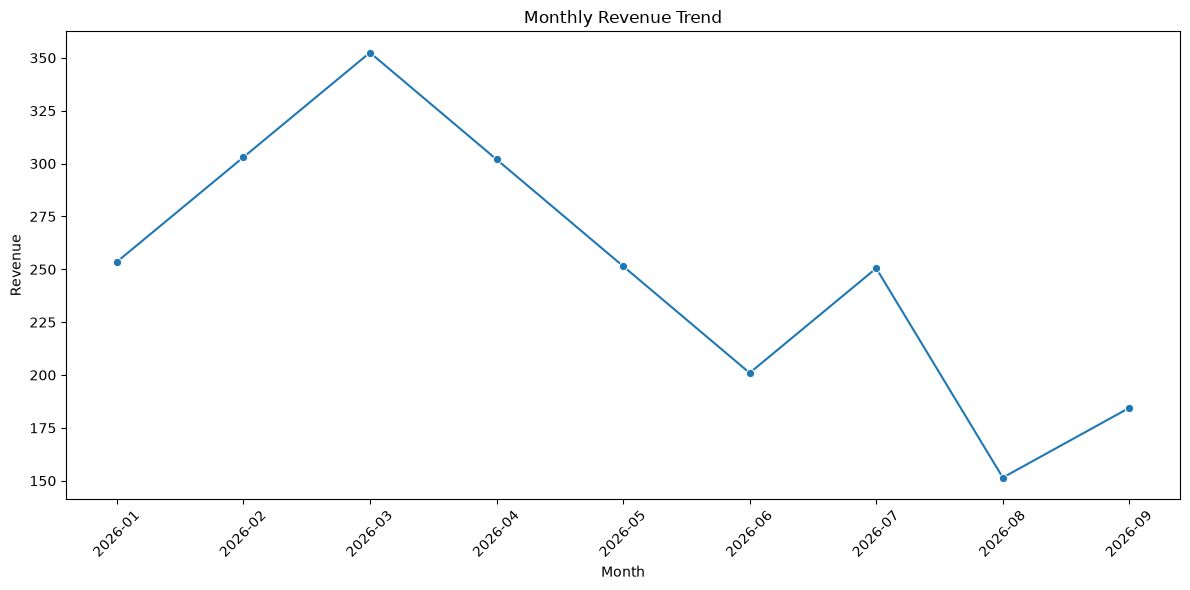

In [32]:
# Montly revenue chart 
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_performance,
    x="year_month",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

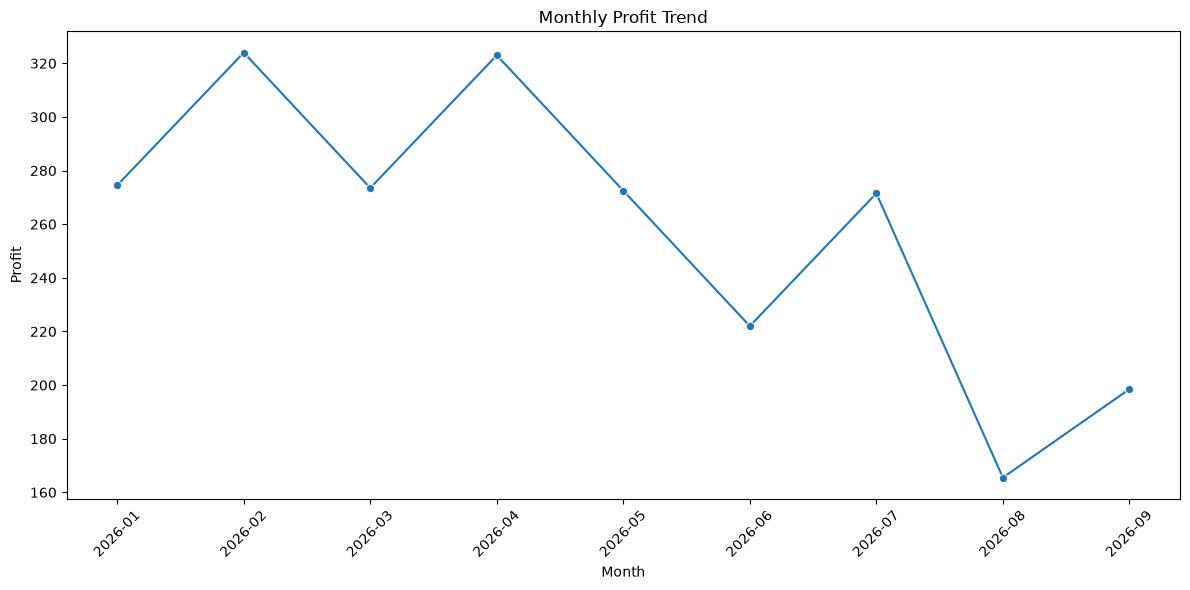

In [33]:
# monthly profit visualization 
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_performance,
    x="year_month",
    y="Profit",
    marker="o"
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

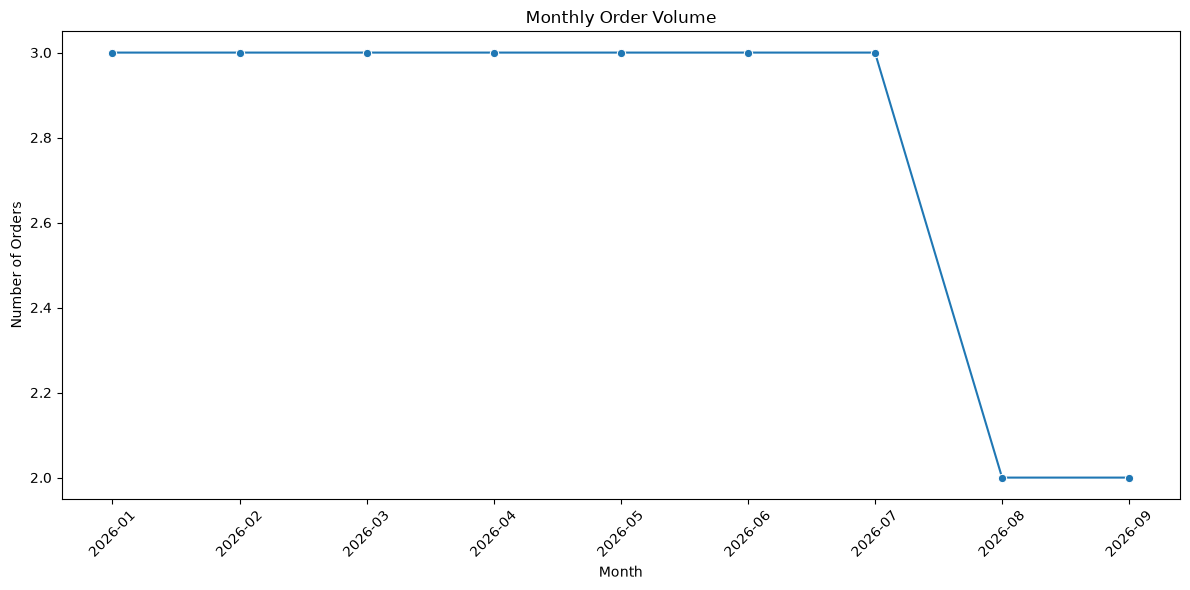

In [34]:
# montly order volume 
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_performance,
    x="year_month",
    y="Orders",
    marker="o"
)

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [35]:
# which payment method most used
payment_analysis = (
    df.groupby("payment_method")
    .agg(
        Orders=("order_id", "nunique"),
        Revenue=("sales", "sum"),
        Profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
)

payment_analysis

,payment_method,Orders,Revenue,Profit
13,payment_method_58,1,166.00,73.00
10,payment_method_45,1,149.50,156.50
12,payment_method_54,1,134.00,141.00
7,payment_method_32,1,133.00,140.00
0,payment_method_10,1,132.00,139.00
9,payment_method_41,1,117.50,124.50
3,payment_method_19,1,116.50,123.50
23,payment_method_97,1,115.50,122.50
11,payment_method_50,1,102.00,109.00
6,payment_method_28,1,101.00,108.00


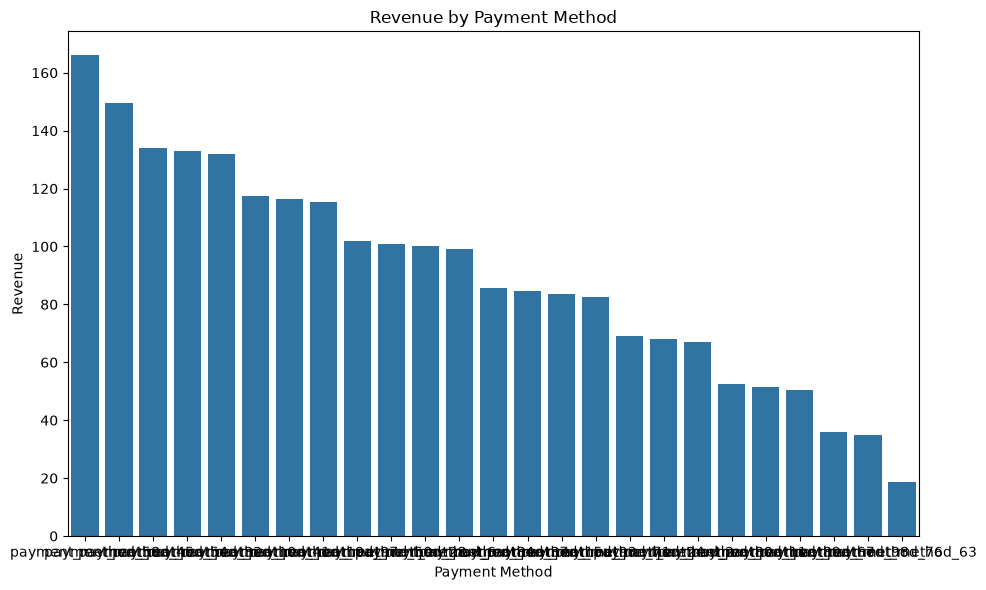

In [37]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=payment_analysis,
    x="payment_method",
    y="Revenue"
)

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

In [38]:
shipping_analysis = (
    df.groupby("ship_mode")
    .agg(
        Orders=("order_id", "nunique"),
        Revenue=("sales", "sum"),
        Profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
)

shipping_analysis

,ship_mode,Orders,Revenue,Profit
4,ship_mode_23,1,166.00,73.00
0,ship_mode_10,1,149.50,156.50
2,ship_mode_19,1,134.00,141.00
24,ship_mode_97,1,133.00,140.00
18,ship_mode_75,1,132.00,139.00
13,ship_mode_6,1,117.50,124.50
21,ship_mode_84,1,116.50,123.50
14,ship_mode_62,1,115.50,122.50
1,ship_mode_15,1,102.00,109.00
23,ship_mode_93,1,101.00,108.00


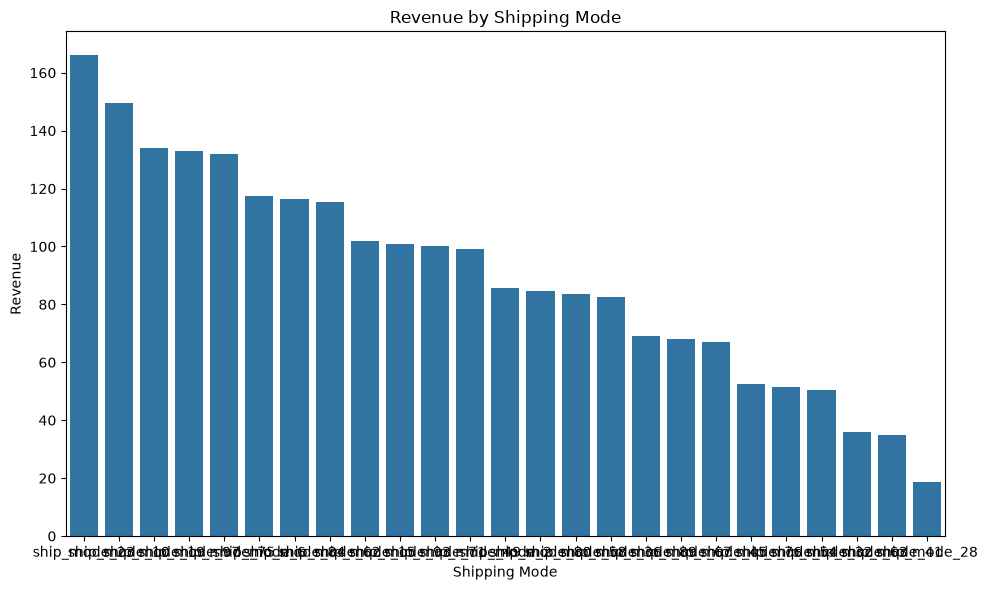

In [39]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=shipping_analysis,
    x="ship_mode",
    y="Revenue"
)

plt.title("Revenue by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

In [40]:
order_status_analysis = (
    df.groupby("order_status")
    .agg(
        Orders=("order_id", "nunique"),
        Revenue=("sales", "sum"),
        Profit=("profit", "sum")
    )
    .reset_index()
)

order_status_analysis

,order_status,Orders,Revenue,Profit
0,order_status_1,1,84.50,91.50
1,order_status_10,1,69.00,76.00
2,order_status_14,1,101.00,108.00
3,order_status_18,1,133.00,140.00
4,order_status_23,1,85.50,92.50
5,order_status_27,1,117.50,124.50
6,order_status_31,1,149.50,156.50
7,order_status_36,1,102.00,109.00
8,order_status_40,1,134.00,141.00
9,order_status_44,1,166.00,73.00


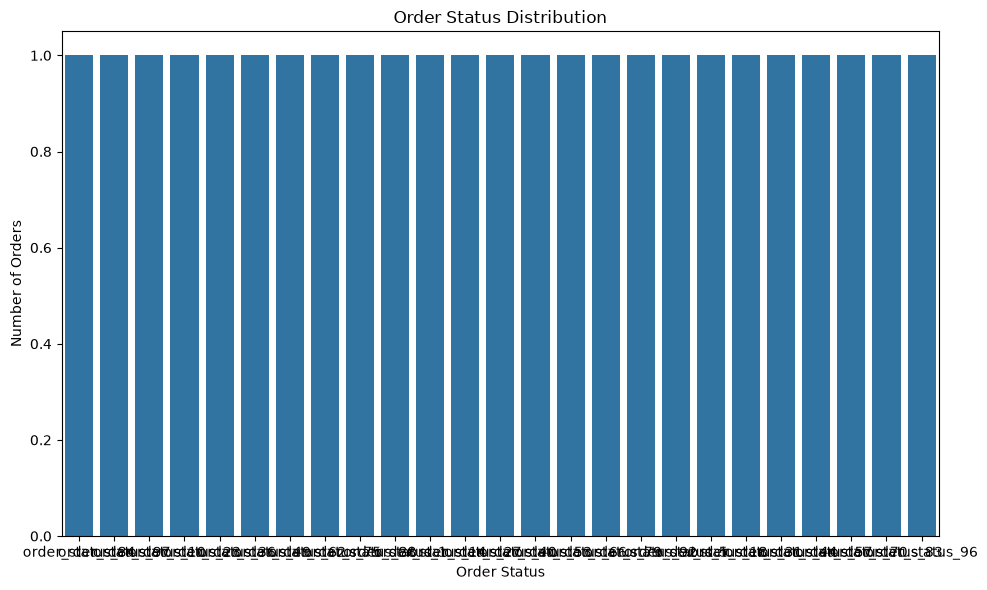

In [41]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="order_status"
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

In [42]:
df["discount"].describe()

count    25.00
mean     95.00
std      35.25
min      23.00
25%      71.50
50%      90.00
75%     121.00
max     154.00
Name: discount, dtype: float64

In [43]:
df["discount_group"] = pd.cut(
    df["discount"],
    bins=[-0.01, 0, 0.10, 0.20, 0.30, 1],
    labels=[
        "No Discount",
        "0-10%",
        "10-20%",
        "20-30%",
        "30%+"
    ]
)

In [45]:
# analysis of discount groups
discount_analysis = (
    df.groupby("discount_group", observed=True)
    .agg(
        Orders=("order_id", "nunique"),
        Revenue=("sales", "sum"),
        Profit=("profit", "sum")
    )
    .reset_index()
)

discount_analysis

,discount_group,Orders,Revenue,Profit


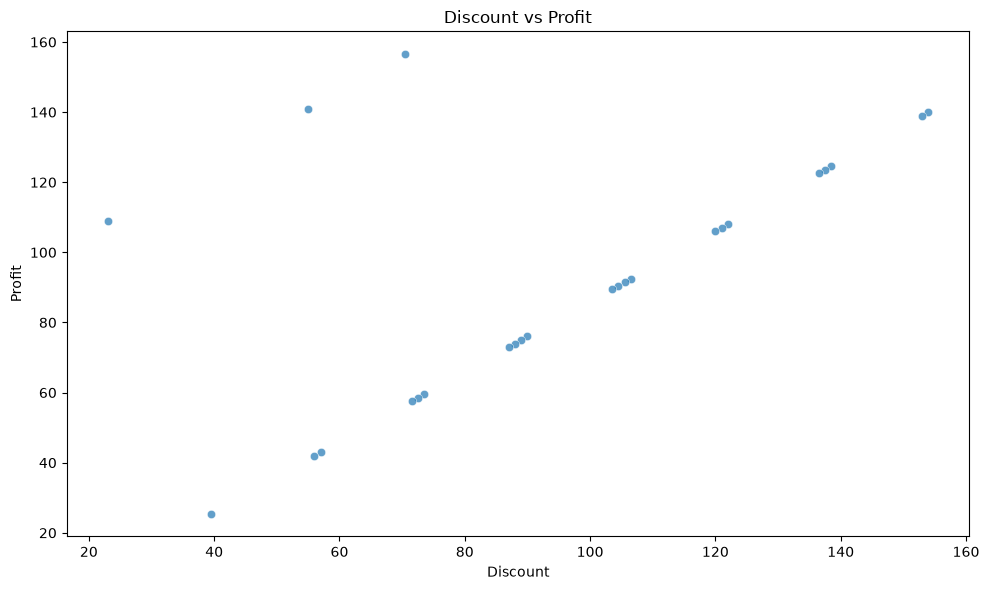

In [46]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="discount",
    y="profit",
    alpha=0.7
)

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

In [48]:
# corelation analysis 
numeric_columns = [
    "quantity",
    "unit_price",
    "discount",
    "sales",
    "profit",
    
]

correlation_matrix = df[numeric_columns].corr()

correlation_matrix


,quantity,unit_price,discount,sales,profit
quantity,1.00,0.51,0.93,0.44,0.56
unit_price,0.51,1.00,0.49,0.22,0.22
discount,0.93,0.49,1.00,0.48,0.55
sales,0.44,0.22,0.48,1.00,0.85
profit,0.56,0.22,0.55,0.85,1.00


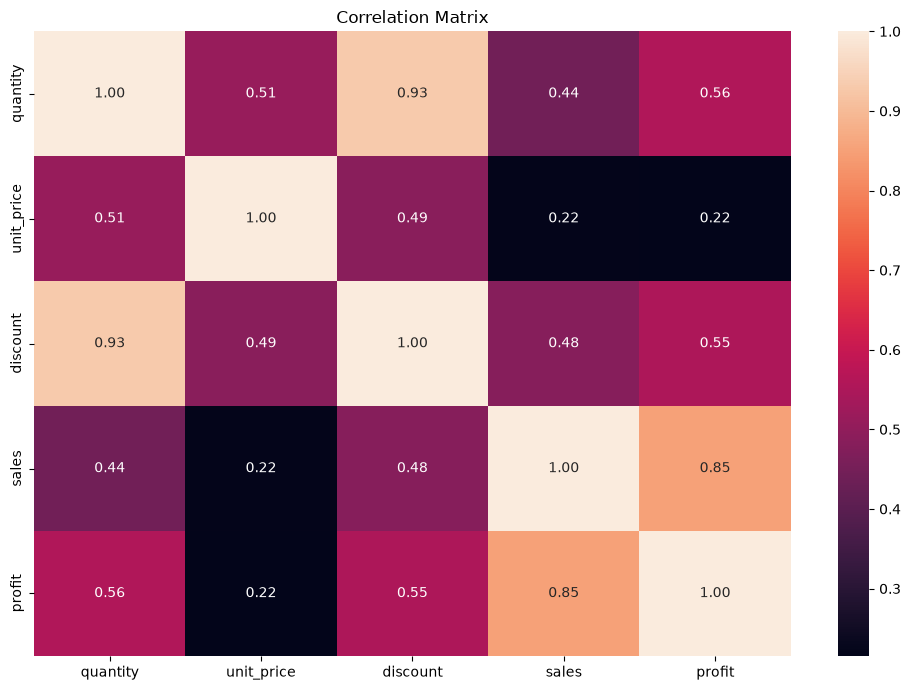

In [49]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [ ]:
# save eda output
monthly_performance.to_csv(
    "../reports/monthly_performance.csv",
    index=False
)

payment_analysis.to_csv(
    "../reports/payment_analysis.csv",
    index=False
)

shipping_analysis.to_csv(
    "../reports/shipping_analysis.csv",
    index=False
)

order_status_analysis.to_csv(
    "../reports/order_status_analysis.csv",
    index=False
)






In [ ]:



#Product & Customer Analysis




In [51]:
product_analysis = (
    df.groupby("product_id")
    .agg(
        Orders=("order_id", "nunique"),
        Units_Sold=("quantity", "sum"),
        Revenue=("sales", "sum"),
        Profit=("profit", "sum")
    )
    .reset_index()
)

product_analysis

,product_id,Orders,Units_Sold,Revenue,Profit
0,PRO-1000,1,1056,36.00,43.00
1,PRO-1001,1,1138,52.50,59.50
2,PRO-1002,1,1246,69.00,76.00
3,PRO-1003,1,1380,85.50,92.50
4,PRO-1004,1,1040,102.00,109.00
5,PRO-1005,1,1126,18.50,25.50
6,PRO-1006,1,1238,35.00,42.00
7,PRO-1007,1,1376,51.50,58.50
8,PRO-1008,1,1540,68.00,75.00
9,PRO-1009,1,1730,84.50,91.50


In [52]:
top_products_revenue = (
    product_analysis
    .sort_values("Revenue", ascending=False)
    .head(10)
)

top_products_revenue

,product_id,Orders,Units_Sold,Revenue,Profit
20,PRO-1020,1,1336,166.00,73.00
19,PRO-1019,1,1060,149.50,156.50
12,PRO-1012,1,1156,134.00,141.00
18,PRO-1018,1,2710,133.00,140.00
24,PRO-1024,1,2700,132.00,139.00
11,PRO-1011,1,2188,117.50,124.50
17,PRO-1017,1,2386,116.50,123.50
23,PRO-1023,1,2320,115.50,122.50
4,PRO-1004,1,1040,102.00,109.00
10,PRO-1010,1,1946,101.00,108.00


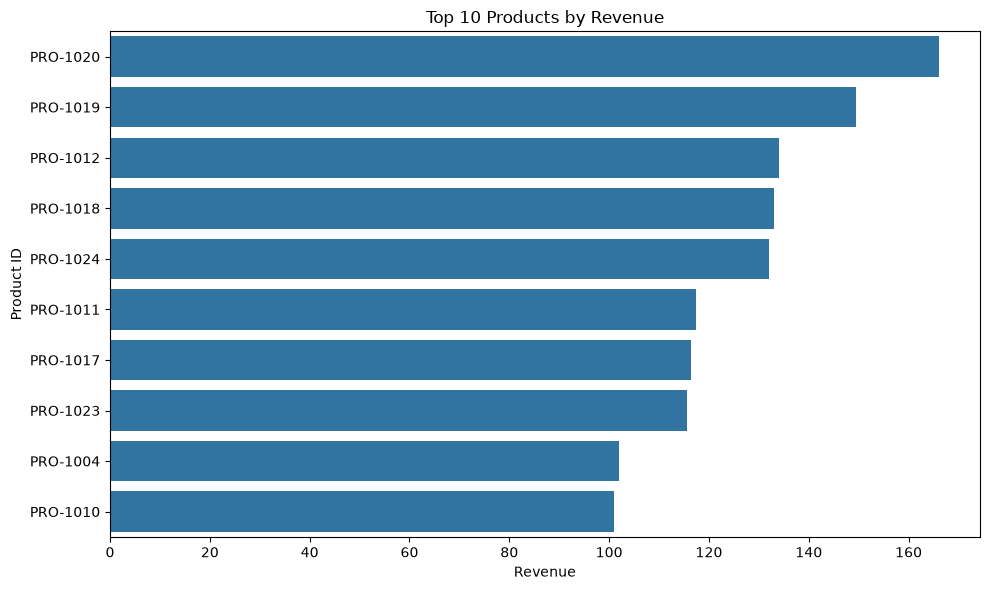

In [53]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_products_revenue,
    x="Revenue",
    y="product_id"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product ID")

plt.tight_layout()
plt.show()

In [54]:
top_products_profit = (
    product_analysis
    .sort_values("Profit", ascending=False)
    .head(10)
)

top_products_profit

,product_id,Orders,Units_Sold,Revenue,Profit
19,PRO-1019,1,1060,149.50,156.50
12,PRO-1012,1,1156,134.00,141.00
18,PRO-1018,1,2710,133.00,140.00
24,PRO-1024,1,2700,132.00,139.00
11,PRO-1011,1,2188,117.50,124.50
17,PRO-1017,1,2386,116.50,123.50
23,PRO-1023,1,2320,115.50,122.50
4,PRO-1004,1,1040,102.00,109.00
10,PRO-1010,1,1946,101.00,108.00
16,PRO-1016,1,2088,100.00,107.00


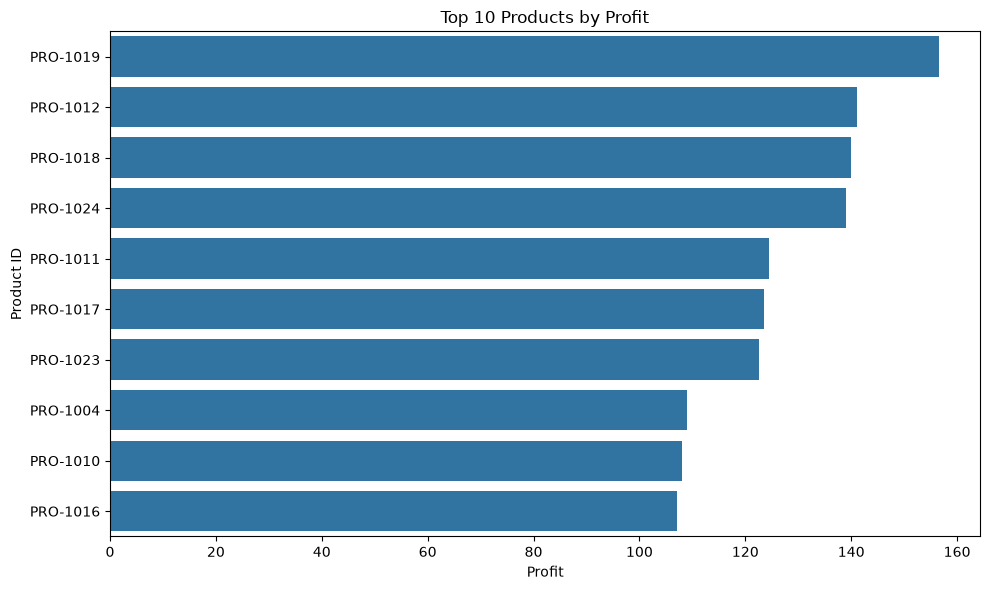

In [55]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_products_profit,
    x="Profit",
    y="product_id"
)

plt.title("Top 10 Products by Profit")
plt.xlabel("Profit")
plt.ylabel("Product ID")

plt.tight_layout()
plt.show()

In [56]:
revenue_rank = (
    product_analysis
    .sort_values("Revenue", ascending=False)
    .head(10)["product_id"]
    .tolist()
)

profit_rank = (
    product_analysis
    .sort_values("Profit", ascending=False)
    .head(10)["product_id"]
    .tolist()
)

print("Top products by revenue:")
print(revenue_rank)

print("\nTop products by profit:")
print(profit_rank)

Top products by revenue:
['PRO-1020', 'PRO-1019', 'PRO-1012', 'PRO-1018', 'PRO-1024', 'PRO-1011', 'PRO-1017', 'PRO-1023', 'PRO-1004', 'PRO-1010']

Top products by profit:
['PRO-1019', 'PRO-1012', 'PRO-1018', 'PRO-1024', 'PRO-1011', 'PRO-1017', 'PRO-1023', 'PRO-1004', 'PRO-1010', 'PRO-1016']


In [57]:
worst_products = (
    product_analysis
    .sort_values("Profit", ascending=True)
    .head(10)
)

worst_products

,product_id,Orders,Units_Sold,Revenue,Profit
5,PRO-1005,1,1126,18.50,25.50
6,PRO-1006,1,1238,35.00,42.00
0,PRO-1000,1,1056,36.00,43.00
13,PRO-1013,1,1350,50.50,57.50
7,PRO-1007,1,1376,51.50,58.50
1,PRO-1001,1,1138,52.50,59.50
20,PRO-1020,1,1336,166.00,73.00
14,PRO-1014,1,1570,67.00,74.00
8,PRO-1008,1,1540,68.00,75.00
2,PRO-1002,1,1246,69.00,76.00


In [58]:
loss_making_products = product_analysis[
    product_analysis["Profit"] < 0
].sort_values("Profit")

In [59]:
loss_making_products

,product_id,Orders,Units_Sold,Revenue,Profit


In [60]:
# product profit margin 
product_analysis["Profit_Margin"] = np.where(
    product_analysis["Revenue"] != 0,
    (
        product_analysis["Profit"]
        / product_analysis["Revenue"]
    ) * 100,
    0
)



In [61]:
product_analysis.head()

,product_id,Orders,Units_Sold,Revenue,Profit,Profit_Margin
0,PRO-1000,1,1056,36.00,43.00,119.44
1,PRO-1001,1,1138,52.50,59.50,113.33
2,PRO-1002,1,1246,69.00,76.00,110.14
3,PRO-1003,1,1380,85.50,92.50,108.19
4,PRO-1004,1,1040,102.00,109.00,106.86


In [62]:
top_margin_products = (
    product_analysis
    .sort_values("Profit_Margin", ascending=False)
    .head(10)
)

top_margin_products

,product_id,Orders,Units_Sold,Revenue,Profit,Profit_Margin
5,PRO-1005,1,1126,18.50,25.50,137.84
6,PRO-1006,1,1238,35.00,42.00,120.00
0,PRO-1000,1,1056,36.00,43.00,119.44
13,PRO-1013,1,1350,50.50,57.50,113.86
7,PRO-1007,1,1376,51.50,58.50,113.59
1,PRO-1001,1,1138,52.50,59.50,113.33
14,PRO-1014,1,1570,67.00,74.00,110.45
8,PRO-1008,1,1540,68.00,75.00,110.29
2,PRO-1002,1,1246,69.00,76.00,110.14
21,PRO-1021,1,1638,82.50,89.50,108.48


In [63]:
df["customer_id"].nunique()

25

In [64]:
customer_analysis = (
    df.groupby("customer_id")
    .agg(
        Orders=("order_id", "nunique"),
        Units_Purchased=("quantity", "sum"),
        Revenue=("sales", "sum"),
        Profit=("profit", "sum"),
        Average_Order_Value=("sales", "mean")
    )
    .reset_index()
)

customer_analysis.head()

,customer_id,Orders,Units_Purchased,Revenue,Profit,Average_Order_Value
0,CUS-1000,1,1056,36.00,43.00,36.00
1,CUS-1001,1,1138,52.50,59.50,52.50
2,CUS-1002,1,1246,69.00,76.00,69.00
3,CUS-1003,1,1380,85.50,92.50,85.50
4,CUS-1004,1,1040,102.00,109.00,102.00


In [65]:
top_customers = (
    customer_analysis
    .sort_values("Revenue", ascending=False)
    .head(10)
)

top_customers

,customer_id,Orders,Units_Purchased,Revenue,Profit,Average_Order_Value
20,CUS-1020,1,1336,166.00,73.00,166.00
19,CUS-1019,1,1060,149.50,156.50,149.50
12,CUS-1012,1,1156,134.00,141.00,134.00
18,CUS-1018,1,2710,133.00,140.00,133.00
24,CUS-1024,1,2700,132.00,139.00,132.00
11,CUS-1011,1,2188,117.50,124.50,117.50
17,CUS-1017,1,2386,116.50,123.50,116.50
23,CUS-1023,1,2320,115.50,122.50,115.50
4,CUS-1004,1,1040,102.00,109.00,102.00
10,CUS-1010,1,1946,101.00,108.00,101.00


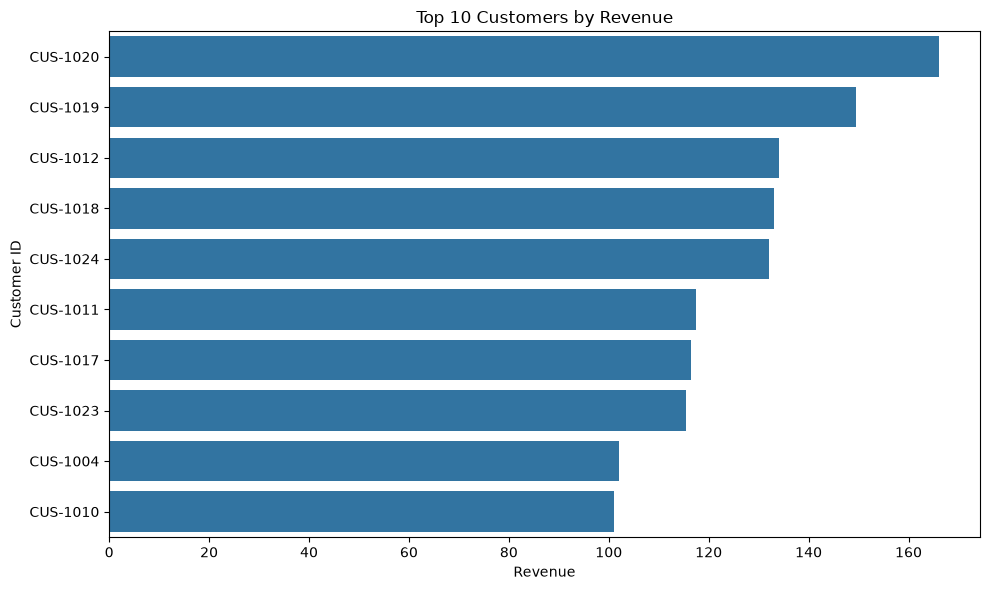

In [66]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_customers,
    x="Revenue",
    y="customer_id"
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

In [67]:
top_customers_profit = (
    customer_analysis
    .sort_values("Profit", ascending=False)
    .head(10)
)

top_customers_profit

,customer_id,Orders,Units_Purchased,Revenue,Profit,Average_Order_Value
19,CUS-1019,1,1060,149.50,156.50,149.50
12,CUS-1012,1,1156,134.00,141.00,134.00
18,CUS-1018,1,2710,133.00,140.00,133.00
24,CUS-1024,1,2700,132.00,139.00,132.00
11,CUS-1011,1,2188,117.50,124.50,117.50
17,CUS-1017,1,2386,116.50,123.50,116.50
23,CUS-1023,1,2320,115.50,122.50,115.50
4,CUS-1004,1,1040,102.00,109.00,102.00
10,CUS-1010,1,1946,101.00,108.00,101.00
16,CUS-1016,1,2088,100.00,107.00,100.00


In [68]:
customer_analysis["Orders"].describe()

count   25.00
mean     1.00
std      0.00
min      1.00
25%      1.00
50%      1.00
75%      1.00
max      1.00
Name: Orders, dtype: float64

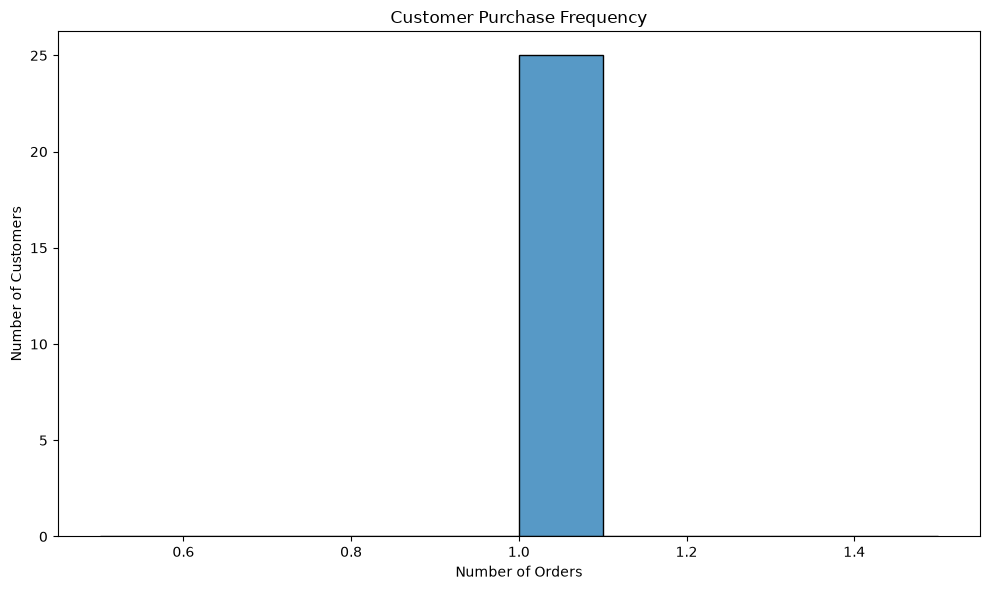

In [69]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=customer_analysis,
    x="Orders",
    bins=10
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [70]:
one_time_customers = customer_analysis[
    customer_analysis["Orders"] == 1
]

repeat_customers = customer_analysis[
    customer_analysis["Orders"] > 1
]

In [71]:
print(
    "One-time customers:",
    len(one_time_customers)
)

print(
    "Repeat customers:",
    len(repeat_customers)
)

One-time customers: 25
Repeat customers: 0


In [72]:
repeat_customer_percentage = (
    len(repeat_customers)
    / len(customer_analysis)
    * 100
)

print(
    f"Repeat Customer Percentage: "
    f"{repeat_customer_percentage:.2f}%"
)

Repeat Customer Percentage: 0.00%


In [73]:
# revenue consentration 
total_customer_revenue = customer_analysis["Revenue"].sum()


In [74]:
top_10_customer_revenue = (
    customer_analysis
    .nlargest(10, "Revenue")["Revenue"]
    .sum()
)

In [75]:
top_10_revenue_percentage = (
    top_10_customer_revenue
    / total_customer_revenue
    * 100
)

print(
    f"Top 10 customers generate "
    f"{top_10_revenue_percentage:.2f}% "
    f"of total revenue."
)

Top 10 customers generate 56.31% of total revenue.


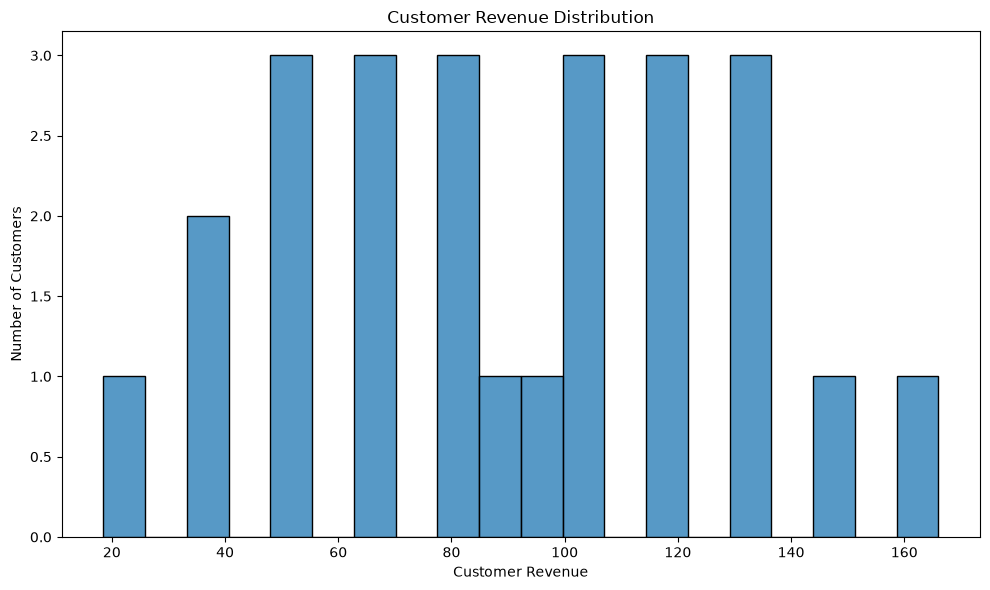

In [76]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=customer_analysis,
    x="Revenue",
    bins=20
)

plt.title("Customer Revenue Distribution")
plt.xlabel("Customer Revenue")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [77]:
customer_analysis["Profit_Margin"] = np.where(
    customer_analysis["Revenue"] != 0,
    (
        customer_analysis["Profit"]
        / customer_analysis["Revenue"]
    ) * 100,
    0
)

In [78]:
customer_analysis.head()


,customer_id,Orders,Units_Purchased,Revenue,Profit,Average_Order_Value,Profit_Margin
0,CUS-1000,1,1056,36.00,43.00,36.00,119.44
1,CUS-1001,1,1138,52.50,59.50,52.50,113.33
2,CUS-1002,1,1246,69.00,76.00,69.00,110.14
3,CUS-1003,1,1380,85.50,92.50,85.50,108.19
4,CUS-1004,1,1040,102.00,109.00,102.00,106.86


In [80]:
# find high value customer 
revenue_threshold = np.percentile(
    customer_analysis["Revenue"],
    75
)

print(
    f"75th percentile revenue threshold: "
    f"₹{revenue_threshold:,.2f}"
)

75th percentile revenue threshold: ₹116.50


In [81]:
high_value_customers = customer_analysis[
    customer_analysis["Revenue"] >= revenue_threshold
]

high_value_customers.head()

,customer_id,Orders,Units_Purchased,Revenue,Profit,Average_Order_Value,Profit_Margin
11,CUS-1011,1,2188,117.50,124.50,117.50,105.96
12,CUS-1012,1,1156,134.00,141.00,134.00,105.22
17,CUS-1017,1,2386,116.50,123.50,116.50,106.01
18,CUS-1018,1,2710,133.00,140.00,133.00,105.26
19,CUS-1019,1,1060,149.50,156.50,149.50,104.68


In [82]:
product_analysis.to_csv(
    "../reports/product_analysis.csv",
    index=False
)

In [83]:
customer_analysis.to_csv(
    "../reports/customer_analysis.csv",
    index=False
)

In [84]:
top_products_revenue.to_csv(
    "../reports/top_products_revenue.csv",
    index=False
)

top_products_profit.to_csv(
    "../reports/top_products_profit.csv",
    index=False
)

In [85]:
top_customers.to_csv(
    "../reports/top_customers.csv",
    index=False
)